In [75]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]

In [76]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.supervised.knn import KNN
from LearnML.selection.split import train_test_split
from LearnML.learn_about.learn_about import learn_about_KNN
from LearnML.metrics.metrics import classification_report



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Path added: /home/mo/Documents/LearnML_Library


KNN (K-Nearest Neighbors) is a simple, non-parametric supervised learning algorithm that makes predictions by finding the K closest training points to a new input and taking a majority vote (classification) or average (regression). Unlike other algorithms, KNN has no training phase — it memorizes the data and does all the work at prediction time.

Key Concepts:
1. Distance Metric: KNN measures closeness using Euclidean, Manhattan, or Minkowski distance. The choice of metric affects which neighbors are selected.
2. K Value: K controls how many neighbors vote. Small K = flexible but noisy. Large K = smooth but less sensitive to local patterns.
3. No Training Phase: KNN just memorizes the data — fit() only stores X and y. Prediction is where all the computation happens.
4. Majority Vote: The most common label among the K neighbors wins. For ties, the first-found label is returned.

Applications:
- Classifying tumors as malignant or benign based on cell features.
- Recommending products ba

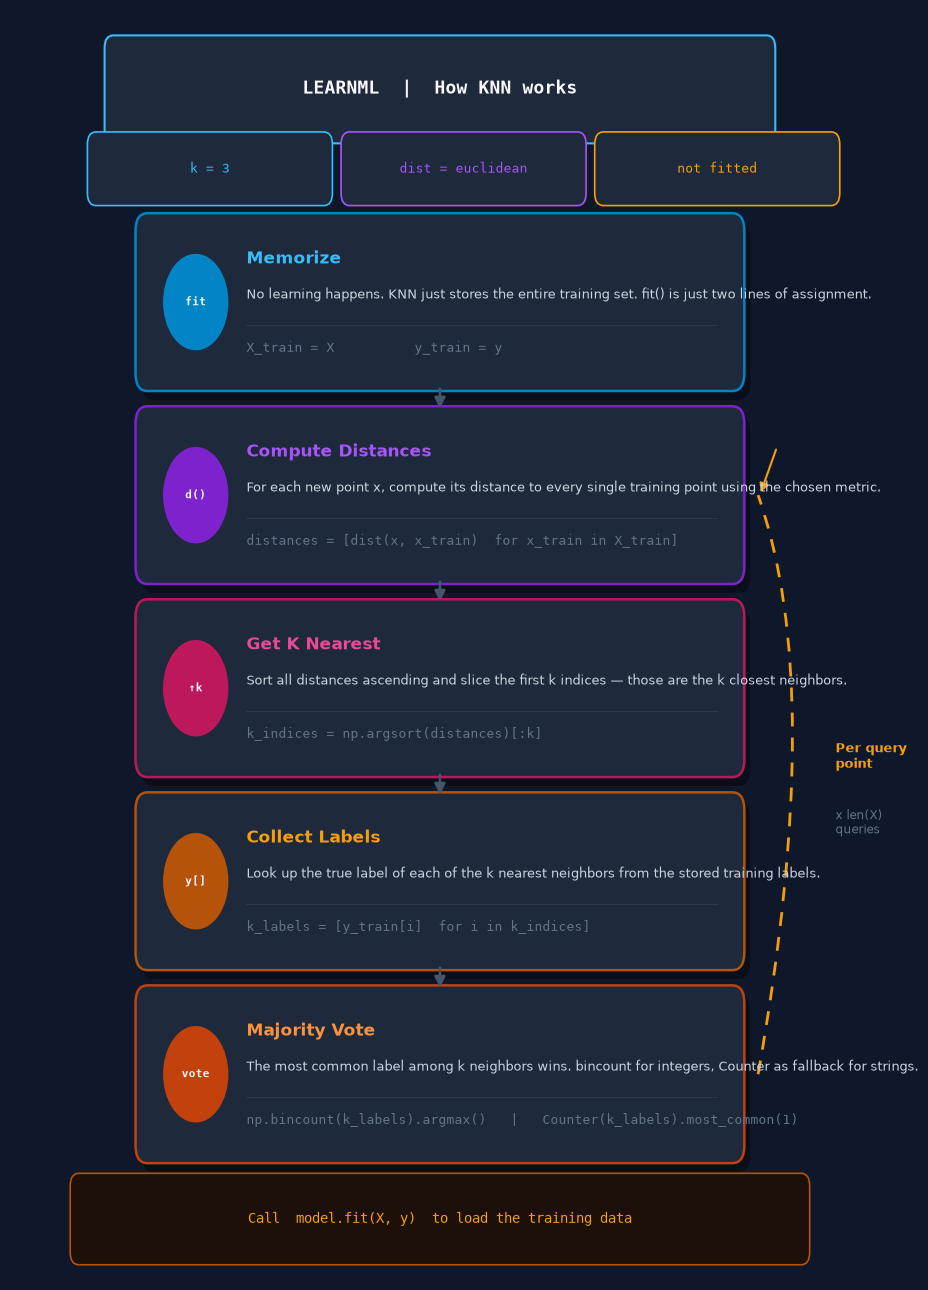

In [77]:
learn_about_KNN()

In [78]:
from sklearn.datasets import make_classification


##1. Generate synthetic classification data (70% informative features)
X, y = make_classification(
    n_samples=1000,         # Total number of rows/samples
    n_features=10,          # Total number of input features
    n_informative=7,        # 70% pure informative features (7 out of 10)
    n_redundant=2,          # 20% redundant features (linear combinations)
    # Note: Remaining 1 feature (10%) is automatically pure random noise
    n_classes=3,            # Number of target categories (e.g., 0, 1, 2)
    n_clusters_per_class=1, # Complexity of each class distribution
    weights=[0.5, 0.3, 0.2],# Class balance (50%, 30%, 20%)
    flip_y=0.02,            # Add 2% random label noise (set to 0.0 for 100% clean labels)
    random_state=42         # Seed for reproducible results
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



Text(0.5, 1.0, 'Training Data Distribution')

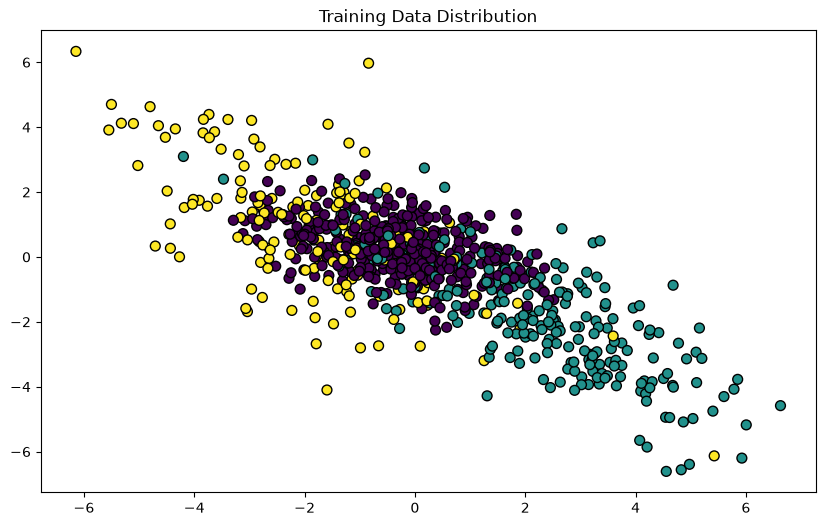

In [79]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     

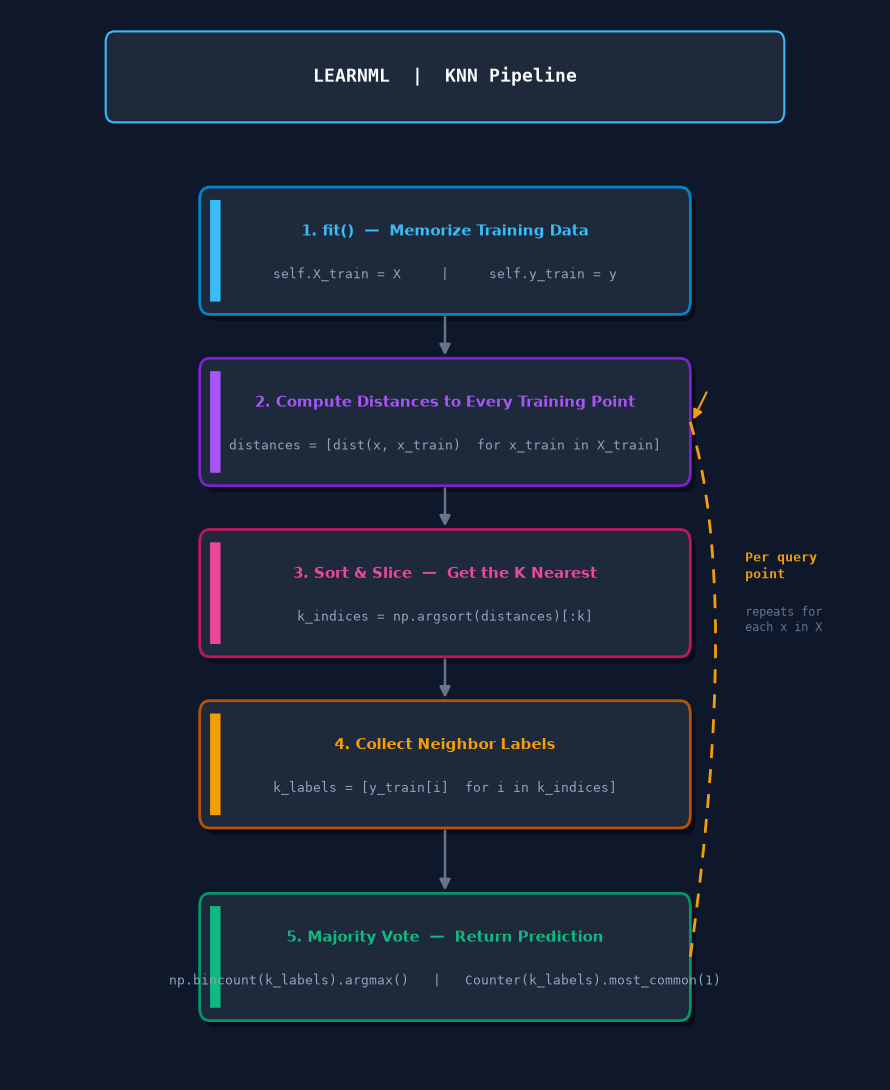

In [80]:
#my knn model
knn_model=KNN(k=5 , distance='euclidean')
knn_model.fit(X_train, y_train)

In [81]:
knn_model.predict(X_test)

array([2, 0, 0, 0, 0, 2, 0, 2, 2, 0, 1, 1, 0, 0, 2, 0, 1, 0, 1, 0, 0, 1,
       2, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 2, 0, 0, 0, 0,
       0, 0, 2, 0, 0, 2, 1, 1, 0, 1, 2, 0, 1, 0, 0, 0, 1, 1, 2, 1, 1, 0,
       1, 1, 0, 1, 0, 2, 0, 0, 1, 2, 0, 0, 1, 2, 1, 0, 0, 2, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 1, 0, 0, 0, 2, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 2, 1, 0, 0, 0, 0, 0, 2, 0, 1, 1, 1, 1, 2, 0, 1, 0, 1, 2, 0,
       0, 1, 1, 0, 2, 0, 0, 2, 1, 0, 1, 1, 1, 0, 2, 2, 1, 2, 0, 0, 1, 0,
       2, 2, 0, 0, 0, 0, 2, 1, 0, 0, 1, 2, 0, 0, 0, 2, 1, 0, 2, 2, 0, 0,
       2, 2])

In [82]:
print(classification_report(y_test , knn_model.predict(X_test)))

Accuracy: 0.91
Precision: 0.9814814814814815
Recall: 0.9298245614035088
F1 Score: 0.954954954954955
None
